# Simple Neural Network in NumPy (Coffee Roasting)
Self-contained version: only needs `numpy` and `matplotlib` (both ship with Anaconda base). No TensorFlow and no Coursera helper files required.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Helper functions

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def load_coffee_data():
    """Recreates the coffee roasting dataset: X = [temperature (C), duration (min)]."""
    rng = np.random.default_rng(2)
    X = rng.random(400).reshape(-1, 2)
    X[:, 1] = X[:, 1] * 4 + 11.5                 # duration 11.5-15.5 min
    X[:, 0] = X[:, 0] * (285 - 150) + 150        # temperature 150-285 C
    Y = np.zeros(len(X))
    for i, (t, d) in enumerate(X):
        y = -3 / (260 - 175) * t + 21
        if 175 < t < 260 and 12 < d < 15 and d <= y:
            Y[i] = 1
    return X, Y.reshape(-1, 1)

def plt_roast(X, Y):
    Y = Y.reshape(-1)
    plt.figure(figsize=(5, 4))
    plt.scatter(X[Y == 1, 0], X[Y == 1, 1], marker="x", c="red", s=50, label="Good roast (y=1)")
    plt.scatter(X[Y == 0, 0], X[Y == 0, 1], marker="o", facecolors="none",
                edgecolors="tab:blue", s=50, label="Bad roast (y=0)")
    plt.xlabel("Temperature (Celsius)")
    plt.ylabel("Duration (minutes)")
    plt.title("Coffee Roasting")
    plt.legend()
    plt.show()

def plt_network(X, Y, netf, grid_n=60):
    """Left: raw probability map. Right: thresholded decisions. Overlaid on training data."""
    Y = Y.reshape(-1)
    xs = np.linspace(X[:, 0].min(), X[:, 0].max(), grid_n)
    ys = np.linspace(X[:, 1].min(), X[:, 1].max(), grid_n)
    xx, yy = np.meshgrid(xs, ys)
    grid = np.c_[xx.ravel(), yy.ravel()]
    prob = netf(grid).reshape(xx.shape)

    fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for a, z, title in [(ax[0], prob, "Network output (probability)"),
                        (ax[1], (prob >= 0.5).astype(int), "Decision (threshold 0.5)")]:
        a.contourf(xx, yy, z, levels=20 if a is ax[0] else 1, cmap="Blues", alpha=0.6)
        a.scatter(X[Y == 1, 0], X[Y == 1, 1], marker="x", c="red", s=40)
        a.scatter(X[Y == 0, 0], X[Y == 0, 1], marker="o", facecolors="none", edgecolors="k", s=40)
        a.set_xlabel("Temperature (Celsius)")
        a.set_title(title)
    ax[0].set_ylabel("Duration (minutes)")
    plt.tight_layout()
    plt.show()

## Dataset

(200, 2) (200, 1)


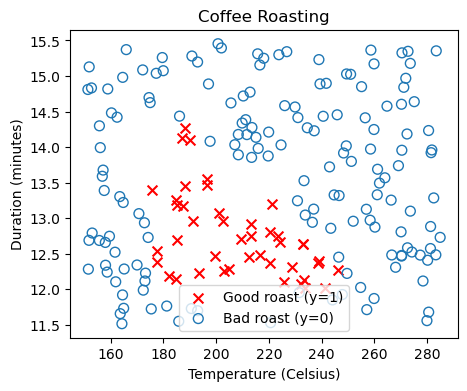

In [3]:
X, Y = load_coffee_data()
print(X.shape, Y.shape)
plt_roast(X, Y)

## Normalize data
Same as Keras `Normalization` layer: subtract the mean, divide by the standard deviation (computed per feature).

In [4]:
print(f"Temperature Max, Min pre normalization: {np.max(X[:,0]):0.2f}, {np.min(X[:,0]):0.2f}")
print(f"Duration    Max, Min pre normalization: {np.max(X[:,1]):0.2f}, {np.min(X[:,1]):0.2f}")

mean = X.mean(axis=0)
std = X.std(axis=0)          # population std, matches Keras

def norm_l(data):
    return (data - mean) / std

Xn = norm_l(X)
print(f"Temperature Max, Min post normalization: {np.max(Xn[:,0]):0.2f}, {np.min(Xn[:,0]):0.2f}")
print(f"Duration    Max, Min post normalization: {np.max(Xn[:,1]):0.2f}, {np.min(Xn[:,1]):0.2f}")

Temperature Max, Min pre normalization: 284.99, 151.32
Duration    Max, Min pre normalization: 15.45, 11.51
Temperature Max, Min post normalization: 1.66, -1.69
Duration    Max, Min post normalization: 1.79, -1.70


## NumPy model (forward prop)

In [5]:
g = sigmoid

def my_dense(a_in, W, b):
    """
    a_in (n,)   : one example
    W    (n, j) : weights, n features, j units
    b    (j,)   : biases
    returns (j,)
    """
    units = W.shape[1]
    a_out = np.zeros(units)
    for j in range(units):
        w = W[:, j]
        z = np.dot(w, a_in) + b[j]
        a_out[j] = g(z)
    return a_out

def my_sequential(x, W1, b1, W2, b2):
    a1 = my_dense(x, W1, b1)
    a2 = my_dense(a1, W2, b2)
    return a2

W1_tmp = np.array([[-8.93, 0.29, 12.9], [-0.1, -7.32, 10.81]])
b1_tmp = np.array([-9.82, -9.28, 0.96])
W2_tmp = np.array([[-31.18], [-27.59], [-32.56]])
b2_tmp = np.array([15.41])

## Predictions

In [6]:
def my_predict(X, W1, b1, W2, b2):
    m = X.shape[0]
    p = np.zeros((m, 1))
    for i in range(m):
        p[i, 0] = my_sequential(X[i], W1, b1, W2, b2)[0]
    return p

X_tst = np.array([
    [200, 13.9],   # positive example
    [200, 17]])    # negative example
X_tstn = norm_l(X_tst)   # remember to normalize
predictions = my_predict(X_tstn, W1_tmp, b1_tmp, W2_tmp, b2_tmp)
print("probabilities =\n", predictions)

yhat = (predictions >= 0.5).astype(int)
print(f"decisions = \n{yhat}")

probabilities =
 [[9.71930379e-01]
 [3.28978702e-08]]
decisions = 
[[1]
 [0]]


## Network function

A `lambda` is a one-line, nameless function written as `lambda inputs: result`, so `lambda x: x * 2` does the same as `def f(x): return x * 2`. It's useful for small throwaway functions you pass into other functions, without writing a full `def` block. In your code, `netf` locks in the normalization and the fixed weights and biases (W and b), so it works like a black box: you give it only raw data and never pass them in again.

```python
# Without the black box: weights and biases must be passed every time
my_predict(norm_l(np.array([[200, 13.9]])), W1_tmp, b1_tmp, W2_tmp, b2_tmp)

# With the black box: only the data goes in
netf(np.array([[200, 13.9]]))   # about 0.97 (good roast)
netf(np.array([[200, 17.0]]))   # near 0 (bad roast)
```

Both calls give the same answer, but `netf` needs only the data because normalization, `W1`, `b1`, `W2` and `b2` are already built into it.

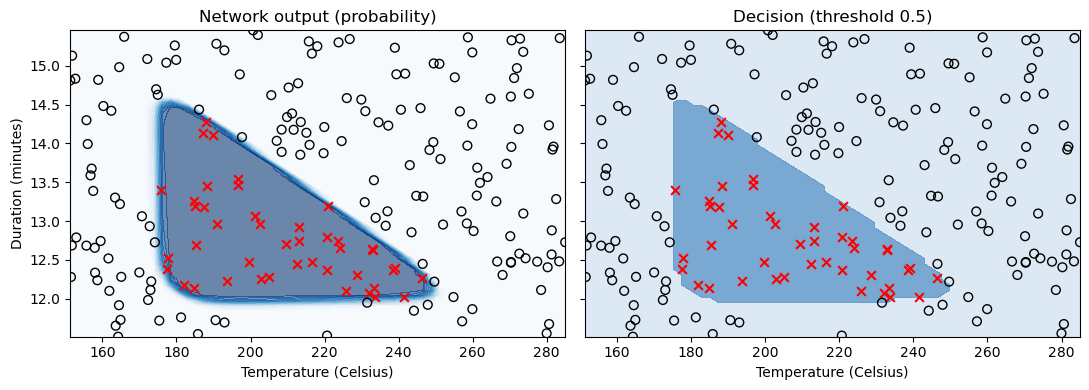

In [7]:
netf = lambda x: my_predict(norm_l(x), W1_tmp, b1_tmp, W2_tmp, b2_tmp)
plt_network(X, Y, netf)

In [10]:
a = netf(np.array([[200, 13.9]]))   # good roast, high probability
b = netf(np.array([[200, 17.0]]))   # too long, probability near 0
c = netf(np.array([[270, 12.0]]))  # too hot, probability near 0

def pred(x):
    if x >= 0.5:
        print("Good Roast")
    else:
        print("Bad Roast")
pred(a)
pred(b)
pred(c)

Good Roast
Bad Roast
Bad Roast
